In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 100)

In [3]:
movies = pd.read_csv("IMDb movies.csv", low_memory=False)
ratings = pd.read_csv("IMDb ratings.csv", low_memory=False)

print("Movies:", movies.shape)
print("Ratings:", ratings.shape)

Movies: (85855, 22)
Ratings: (85855, 49)


In [4]:
display(movies.head())
display(ratings.head())

print("\n--- Movies: Datentypen und Vollständigkeit ---")
movies.info()

print("\n--- Ratings: Datentypen und Vollständigkeit ---")
ratings.info()

,imdb_title_id,title,original_title,year,date_published,genre,duration,country,language,director,writer,production_company,actors,description,avg_vote,votes,budget,usa_gross_income,worlwide_gross_income,metascore,reviews_from_users,reviews_from_critics
0,tt0000009,Miss Jerry,Miss Jerry,1894,1894-10-09,Romance,45,USA,NaN,Alexander Black,Alexander Black,Alexander Black Photoplays,"Blanche Bayliss, William Courtenay, Chauncey Depew",The adventures of a female reporter in the 1890s.,5.9,154,NaN,NaN,NaN,NaN,1.0,2.0
1,tt0000574,The Story of the Kelly Gang,The Story of the Kelly Gang,1906,1906-12-26,"Biography, Crime, Drama",70,Australia,NaN,Charles Tait,Charles Tait,J. and N. Tait,"Elizabeth Tait, John Tait, Norman Campbell, Bella Cola, Will Coyne, Sam Crewes, Jack Ennis, John...",True story of notorious Australian outlaw Ned Kelly (1855-80).,6.1,589,$ 2250,NaN,NaN,NaN,7.0,7.0
2,tt0001892,Den sorte drøm,Den sorte drøm,1911,1911-08-19,Drama,53,"Germany, Denmark",NaN,Urban Gad,"Urban Gad, Gebhard Schätzler-Perasini",Fotorama,"Asta Nielsen, Valdemar Psilander, Gunnar Helsengreen, Emil Albes, Hugo Flink, Mary Hagen",Two men of high rank are both wooing the beautiful and famous equestrian acrobat Stella. While S...,5.8,188,NaN,NaN,NaN,NaN,5.0,2.0
3,tt0002101,Cleopatra,Cleopatra,1912,1912-11-13,"Drama, History",100,USA,English,Charles L. Gaskill,Victorien Sardou,Helen Gardner Picture Players,"Helen Gardner, Pearl Sindelar, Miss Fielding, Miss Robson, Helene Costello, Charles Sindelar, Mr...",The fabled queen of Egypt's affair with Roman general Marc Antony is ultimately disastrous for b...,5.2,446,$ 45000,NaN,NaN,NaN,25.0,3.0
4,tt0002130,L'Inferno,L'Inferno,1911,1911-03-06,"Adventure, Drama, Fantasy",68,Italy,Italian,"Francesco Bertolini, Adolfo Padovan",Dante Alighieri,Milano Film,"Salvatore Papa, Arturo Pirovano, Giuseppe de Liguoro, Pier Delle Vigne, Augusto Milla, Attilio M...",Loosely adapted from Dante's Divine Comedy and inspired by the illustrations of Gustav Doré the ...,7.0,2237,NaN,NaN,NaN,NaN,31.0,14.0


,imdb_title_id,weighted_average_vote,total_votes,mean_vote,median_vote,votes_10,votes_9,votes_8,votes_7,votes_6,votes_5,votes_4,votes_3,votes_2,votes_1,allgenders_0age_avg_vote,allgenders_0age_votes,allgenders_18age_avg_vote,allgenders_18age_votes,allgenders_30age_avg_vote,allgenders_30age_votes,allgenders_45age_avg_vote,allgenders_45age_votes,males_allages_avg_vote,males_allages_votes,males_0age_avg_vote,males_0age_votes,males_18age_avg_vote,males_18age_votes,males_30age_avg_vote,males_30age_votes,males_45age_avg_vote,males_45age_votes,females_allages_avg_vote,females_allages_votes,females_0age_avg_vote,females_0age_votes,females_18age_avg_vote,females_18age_votes,females_30age_avg_vote,females_30age_votes,females_45age_avg_vote,females_45age_votes,top1000_voters_rating,top1000_voters_votes,us_voters_rating,us_voters_votes,non_us_voters_rating,non_us_voters_votes
0,tt0000009,5.9,154,5.9,6.0,12,4,10,43,28,28,9,1,5,14,7.2,4.0,6.0,38.0,5.7,50.0,6.6,35.0,6.2,97.0,7.0,1.0,5.9,24.0,5.6,36.0,6.7,31.0,6.0,35.0,7.3,3.0,5.9,14.0,5.7,13.0,4.5,4.0,5.7,34.0,6.4,51.0,6.0,70.0
1,tt0000574,6.1,589,6.3,6.0,57,18,58,137,139,103,28,20,13,16,6.0,1.0,6.1,114.0,6.0,239.0,6.3,115.0,6.1,425.0,6.0,1.0,6.2,102.0,6.0,210.0,6.2,100.0,6.2,50.0,NaN,NaN,5.9,12.0,6.2,23.0,6.6,14.0,6.4,66.0,6.0,96.0,6.2,331.0
2,tt0001892,5.8,188,6.0,6.0,6,6,17,44,52,32,16,5,6,4,NaN,NaN,5.5,25.0,5.8,72.0,6.2,62.0,5.9,146.0,NaN,NaN,5.5,21.0,5.9,67.0,6.2,55.0,5.7,15.0,NaN,NaN,5.8,4.0,5.8,4.0,6.8,7.0,5.4,32.0,6.2,31.0,5.9,123.0
3,tt0002101,5.2,446,5.3,5.0,15,8,16,62,98,117,63,26,25,16,NaN,NaN,5.3,23.0,5.0,111.0,5.3,193.0,5.1,299.0,NaN,NaN,5.2,20.0,4.9,96.0,5.2,171.0,5.9,39.0,NaN,NaN,5.7,3.0,5.5,14.0,6.1,21.0,4.9,57.0,5.5,207.0,4.7,105.0
4,tt0002130,7.0,2237,6.9,7.0,210,225,436,641,344,169,66,39,20,87,7.5,4.0,7.0,402.0,7.0,895.0,7.1,482.0,7.0,1607.0,8.0,2.0,7.0,346.0,7.0,804.0,7.0,396.0,7.2,215.0,7.0,2.0,7.0,52.0,7.3,82.0,7.4,77.0,6.9,139.0,7.0,488.0,7.0,1166.0



--- Movies: Datentypen und Vollständigkeit ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 85855 entries, 0 to 85854
Data columns (total 22 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   imdb_title_id          85855 non-null  object 
 1   title                  85855 non-null  object 
 2   original_title         85855 non-null  object 
 3   year                   85855 non-null  object 
 4   date_published         85855 non-null  object 
 5   genre                  85855 non-null  object 
 6   duration               85855 non-null  int64  
 7   country                85791 non-null  object 
 8   language               84954 non-null  object 
 9   director               85768 non-null  object 
 10  writer                 84283 non-null  object 
 11  production_company     81400 non-null  object 
 12  actors                 85786 non-null  object 
 13  description            83740 non-null  object 
 14  avg_vo

### Ergebnis: erster Datenüberblick
Beide Dateien enthalten jeweils **85.855 Datensätze**. Die Movie-Datei hat 22 Spalten, die Rating-Datei 49. Die gemeinsame IMDb-ID ermöglicht es, Filmbeschreibungen und zusätzliche Bewertungsinformationen zusammenzuführen. Für unser Projekt sind besonders Genre, Produktionsland, Sprache und Bewertung relevant.

## Vorerst Relevante Spalten auswählen

In [5]:
movie_columns = [
    "imdb_title_id",
    "title",
    "year",
    "genre",
    "duration",
    "country",
    "language",
    "avg_vote",
    "votes"
]

ratings_columns = [
    "imdb_title_id",
    "weighted_average_vote",
    "total_votes",
    "mean_vote",
    "median_vote"
]

display(movies[movie_columns].head(10))
display(ratings[ratings_columns].head(10))

,imdb_title_id,title,year,genre,duration,country,language,avg_vote,votes
0,tt0000009,Miss Jerry,1894,Romance,45,USA,NaN,5.9,154
1,tt0000574,The Story of the Kelly Gang,1906,"Biography, Crime, Drama",70,Australia,NaN,6.1,589
2,tt0001892,Den sorte drøm,1911,Drama,53,"Germany, Denmark",NaN,5.8,188
3,tt0002101,Cleopatra,1912,"Drama, History",100,USA,English,5.2,446
4,tt0002130,L'Inferno,1911,"Adventure, Drama, Fantasy",68,Italy,Italian,7.0,2237
5,tt0002199,"From the Manger to the Cross; or, Jesus of Nazareth",1912,"Biography, Drama",60,USA,English,5.7,484
6,tt0002423,Madame DuBarry,1919,"Biography, Drama, Romance",85,Germany,German,6.8,753
7,tt0002445,Quo Vadis?,1913,"Drama, History",120,Italy,Italian,6.2,273
8,tt0002452,Independenta Romaniei,1912,"History, War",120,Romania,NaN,6.7,198
9,tt0002461,Richard III,1912,Drama,55,"France, USA",English,5.5,225


,imdb_title_id,weighted_average_vote,total_votes,mean_vote,median_vote
0,tt0000009,5.9,154,5.9,6.0
1,tt0000574,6.1,589,6.3,6.0
2,tt0001892,5.8,188,6.0,6.0
3,tt0002101,5.2,446,5.3,5.0
4,tt0002130,7.0,2237,6.9,7.0
5,tt0002199,5.7,484,5.8,6.0
6,tt0002423,6.8,753,6.8,7.0
7,tt0002445,6.2,273,6.2,6.0
8,tt0002452,6.7,198,7.1,7.0
9,tt0002461,5.5,225,5.4,6.0


## Fehlende Werte untersuchen

In [6]:
missing_movies = (
    movies.isna()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

missing_ratings = (
    ratings.isna()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

print("Fehlende Werte in Movies (%):")
display(missing_movies[missing_movies > 0].round(2))

print("Fehlende Werte in Ratings (%):")
display(missing_ratings[missing_ratings > 0].round(2))

Fehlende Werte in Movies (%):


metascore                84.50
usa_gross_income         82.15
budget                   72.38
worlwide_gross_income    63.87
reviews_from_critics     13.74
reviews_from_users        8.85
production_company        5.19
description               2.46
writer                    1.83
language                  1.05
director                  0.10
actors                    0.08
country                   0.07
dtype: float64

Fehlende Werte in Ratings (%):


females_0age_avg_vote        74.24
females_0age_votes           74.24
males_0age_votes             68.07
males_0age_avg_vote          68.07
allgenders_0age_avg_vote     61.14
allgenders_0age_votes        61.14
females_18age_votes           7.60
females_18age_avg_vote        7.60
females_45age_votes           3.26
females_45age_avg_vote        3.26
males_18age_votes             1.71
males_18age_avg_vote          1.71
females_30age_votes           1.10
females_30age_avg_vote        1.10
allgenders_18age_avg_vote     0.82
allgenders_18age_votes        0.82
top1000_voters_rating         0.79
top1000_voters_votes          0.79
us_voters_rating              0.24
us_voters_votes               0.24
males_45age_avg_vote          0.12
males_45age_votes             0.12
females_allages_votes         0.09
females_allages_avg_vote      0.09
allgenders_45age_avg_vote     0.09
allgenders_45age_votes        0.09
males_30age_avg_vote          0.01
males_30age_votes             0.01
allgenders_30age_vot

### Ergebnis: fehlende Werte
Die stärksten Lücken betreffen kommerzielle und redaktionelle Zusatzdaten: **Metascore fehlt bei 84,50 %**, US-Einnahmen bei **82,15 %**, Budget bei **72,38 %** und weltweite Einnahmen bei **63,87 %** der Filme. Dagegen fehlen die IMDb-Filmbewertungen (`avg_vote`) nicht. Die Sprachangabe fehlt nur bei **1,05 %** der Filme. Für kulturell vielfältige Empfehlungen sind Land und Sprache damit vergleichsweise gut nutzbar; Budget und Metascore sollten nicht als Pflichtmerkmale vorausgesetzt werden.

## Duplikate und Verknüpfbarkeit prüfen

In [7]:
print("Doppelte Movie-IDs:", movies["imdb_title_id"].duplicated().sum())
print("Doppelte Rating-IDs:", ratings["imdb_title_id"].duplicated().sum())

print(
    "Movie-IDs ohne Ratings:",
    (~movies["imdb_title_id"].isin(ratings["imdb_title_id"])).sum()
)

print(
    "Rating-IDs ohne Movie-Datensatz:",
    (~ratings["imdb_title_id"].isin(movies["imdb_title_id"])).sum()
)

Doppelte Movie-IDs: 0
Doppelte Rating-IDs: 0
Movie-IDs ohne Ratings: 0
Rating-IDs ohne Movie-Datensatz: 0


### Ergebnis: Duplikate und Verknüpfung
Es gibt **0 doppelte IMDb-IDs** in beiden Dateien. Außerdem hat keine Movie-ID einen fehlenden Rating-Datensatz und keine Rating-ID einen fehlenden Movie-Datensatz. Die beiden Tabellen lassen sich somit über die IMDb-ID vollständig und eindeutig verknüpfen.

## Beide Dateien zusammenführen

validate="one_to_one" stellt sicher, dass jede IMDb-ID in beiden Dateien höchstens einmal vorkommt.

In [8]:
df = movies.merge(
    ratings,
    on="imdb_title_id",
    how="left",
    suffixes=("_movie", "_ratings"),
    validate="one_to_one"
)

print("Datensätze nach dem Merge:", df.shape)
display(df.head())

Datensätze nach dem Merge: (85855, 70)


,imdb_title_id,title,original_title,year,date_published,genre,duration,country,language,director,writer,production_company,actors,description,avg_vote,votes,budget,usa_gross_income,worlwide_gross_income,metascore,reviews_from_users,reviews_from_critics,weighted_average_vote,total_votes,mean_vote,...,males_allages_votes,males_0age_avg_vote,males_0age_votes,males_18age_avg_vote,males_18age_votes,males_30age_avg_vote,males_30age_votes,males_45age_avg_vote,males_45age_votes,females_allages_avg_vote,females_allages_votes,females_0age_avg_vote,females_0age_votes,females_18age_avg_vote,females_18age_votes,females_30age_avg_vote,females_30age_votes,females_45age_avg_vote,females_45age_votes,top1000_voters_rating,top1000_voters_votes,us_voters_rating,us_voters_votes,non_us_voters_rating,non_us_voters_votes
0,tt0000009,Miss Jerry,Miss Jerry,1894,1894-10-09,Romance,45,USA,NaN,Alexander Black,Alexander Black,Alexander Black Photoplays,"Blanche Bayliss, William Courtenay, Chauncey Depew",The adventures of a female reporter in the 1890s.,5.9,154,NaN,NaN,NaN,NaN,1.0,2.0,5.9,154,5.9,...,97.0,7.0,1.0,5.9,24.0,5.6,36.0,6.7,31.0,6.0,35.0,7.3,3.0,5.9,14.0,5.7,13.0,4.5,4.0,5.7,34.0,6.4,51.0,6.0,70.0
1,tt0000574,The Story of the Kelly Gang,The Story of the Kelly Gang,1906,1906-12-26,"Biography, Crime, Drama",70,Australia,NaN,Charles Tait,Charles Tait,J. and N. Tait,"Elizabeth Tait, John Tait, Norman Campbell, Bella Cola, Will Coyne, Sam Crewes, Jack Ennis, John...",True story of notorious Australian outlaw Ned Kelly (1855-80).,6.1,589,$ 2250,NaN,NaN,NaN,7.0,7.0,6.1,589,6.3,...,425.0,6.0,1.0,6.2,102.0,6.0,210.0,6.2,100.0,6.2,50.0,NaN,NaN,5.9,12.0,6.2,23.0,6.6,14.0,6.4,66.0,6.0,96.0,6.2,331.0
2,tt0001892,Den sorte drøm,Den sorte drøm,1911,1911-08-19,Drama,53,"Germany, Denmark",NaN,Urban Gad,"Urban Gad, Gebhard Schätzler-Perasini",Fotorama,"Asta Nielsen, Valdemar Psilander, Gunnar Helsengreen, Emil Albes, Hugo Flink, Mary Hagen",Two men of high rank are both wooing the beautiful and famous equestrian acrobat Stella. While S...,5.8,188,NaN,NaN,NaN,NaN,5.0,2.0,5.8,188,6.0,...,146.0,NaN,NaN,5.5,21.0,5.9,67.0,6.2,55.0,5.7,15.0,NaN,NaN,5.8,4.0,5.8,4.0,6.8,7.0,5.4,32.0,6.2,31.0,5.9,123.0
3,tt0002101,Cleopatra,Cleopatra,1912,1912-11-13,"Drama, History",100,USA,English,Charles L. Gaskill,Victorien Sardou,Helen Gardner Picture Players,"Helen Gardner, Pearl Sindelar, Miss Fielding, Miss Robson, Helene Costello, Charles Sindelar, Mr...",The fabled queen of Egypt's affair with Roman general Marc Antony is ultimately disastrous for b...,5.2,446,$ 45000,NaN,NaN,NaN,25.0,3.0,5.2,446,5.3,...,299.0,NaN,NaN,5.2,20.0,4.9,96.0,5.2,171.0,5.9,39.0,NaN,NaN,5.7,3.0,5.5,14.0,6.1,21.0,4.9,57.0,5.5,207.0,4.7,105.0
4,tt0002130,L'Inferno,L'Inferno,1911,1911-03-06,"Adventure, Drama, Fantasy",68,Italy,Italian,"Francesco Bertolini, Adolfo Padovan",Dante Alighieri,Milano Film,"Salvatore Papa, Arturo Pirovano, Giuseppe de Liguoro, Pier Delle Vigne, Augusto Milla, Attilio M...",Loosely adapted from Dante's Divine Comedy and inspired by the illustrations of Gustav Doré the ...,7.0,2237,NaN,NaN,NaN,NaN,31.0,14.0,7.0,2237,6.9,...,1607.0,8.0,2.0,7.0,346.0,7.0,804.0,7.0,396.0,7.2,215.0,7.0,2.0,7.0,52.0,7.3,82.0,7.4,77.0,6.9,139.0,7.0,488.0,7.0,1166.0


### Ergebnis: zusammengeführter Datensatz
Nach dem Merge enthält der Datensatz **85.855 Filme und 70 Spalten**. Die Anzahl der Filme bleibt unverändert, weil für jeden Film genau ein passender Rating-Datensatz existiert. Die zusätzlichen Spalten stehen für ergänzende Bewertungskennzahlen.

## Verteilung der IMDb-Bewertungen

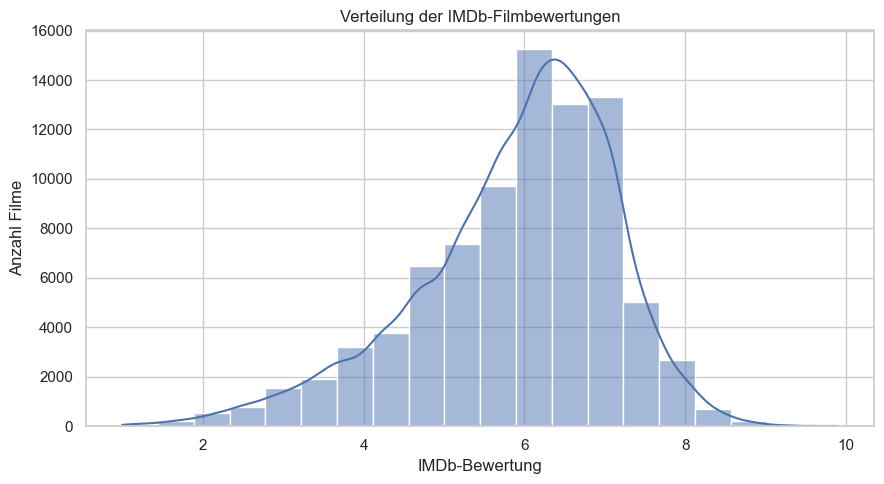

In [9]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="avg_vote",
    bins=20,
    kde=True
)

plt.title("Verteilung der IMDb-Filmbewertungen")
plt.xlabel("IMDb-Bewertung")
plt.ylabel("Anzahl Filme")
plt.tight_layout()
plt.show()

### Ergebnis: Verteilung der IMDb-Bewertungen
Die durchschnittliche IMDb-Bewertung (`avg_vote`) liegt bei **5,90 von 10**, der Median bei **6,10**. Die mittleren 50 % der Filme liegen zwischen **5,20 und 6,80**; die beobachteten Werte reichen von **1,0 bis 9,9**. Die Bewertungen bieten damit eine breite Vergleichsskala. Sie zeigen allerdings die allgemeine IMDb-Bewertung und nicht, ob ein bestimmter Film zu den persönlichen Vorlieben eines Nutzers passt.

## Häufigste Produktionsländer
Da in der Spalte country mehrere Länder pro Film vorkommen können, werden die Einträge zunächst aufgeteilt.

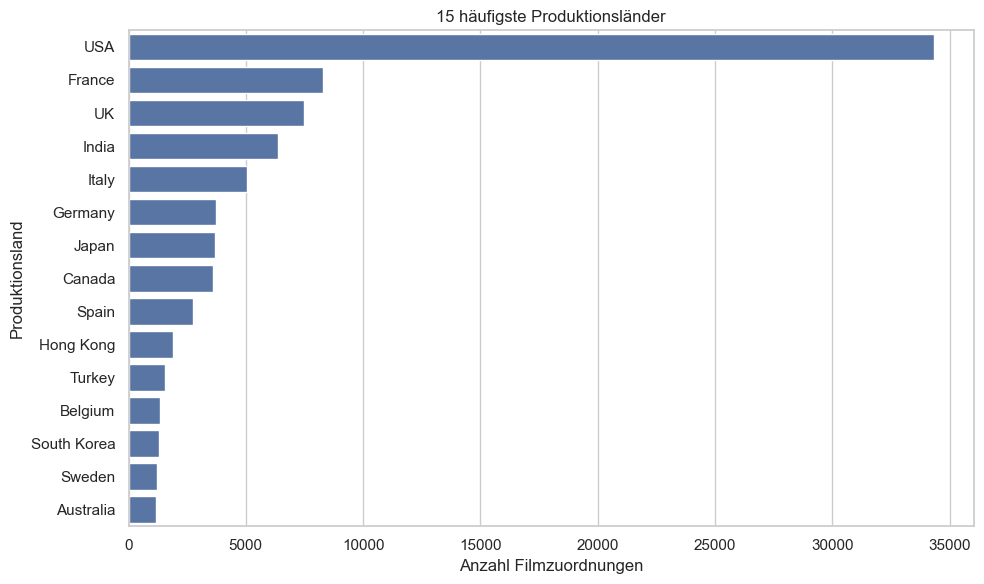

In [10]:
country_df = df.dropna(subset=["country"]).copy()

country_df["country"] = country_df["country"].str.split(",")

country_df = country_df.explode("country")
country_df["country"] = country_df["country"].str.strip()

top_countries = country_df["country"].value_counts().head(15)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_countries.values, y=top_countries.index)

plt.title("15 häufigste Produktionsländer")
plt.xlabel("Anzahl Filmzuordnungen")
plt.ylabel("Produktionsland")
plt.tight_layout()
plt.show()

### Ergebnis: häufigste Produktionsländer
Die Länderspalte enthält Angaben zu **85.791 Filmen** und umfasst **194 unterschiedliche Länderbezeichnungen**. Am häufigsten sind die USA (**34.325 Film-Länder-Zuordnungen**), Frankreich (**8.311**), das Vereinigte Königreich (**7.490**), Indien (**6.373**) und Italien (**5.056**) vertreten. Japan ist mit **3.701** Zuordnungen ebenfalls stark vertreten. Da ein Film mehreren Ländern zugeordnet sein kann, sind dies Zuordnungen und nicht zwingend die Anzahl exklusiv in einem Land produzierter Filme. Für unser Projekt zeigt die Datenbasis eine deutliche US-Dominanz, enthält aber zugleich viele nicht-englischsprachige Filmkulturen.

## Bewertungen nach Produktionsland vergleichen

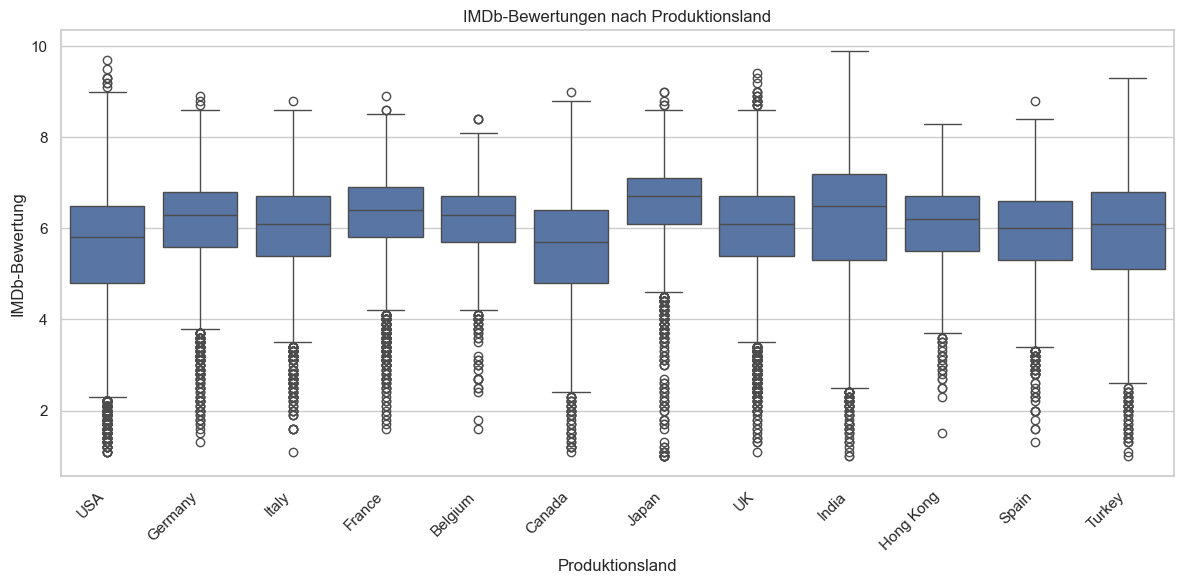

In [11]:
country_ratings = country_df.dropna(subset=["avg_vote"])

# Nur Länder mit mindestens 100 Filmen berücksichtigen
country_counts = country_ratings["country"].value_counts()
eligible_countries = country_counts[country_counts >= 100].index

country_ratings = country_ratings[
    country_ratings["country"].isin(eligible_countries)
]

# Länder mit den meisten Filmen auswählen
selected_countries = (
    country_ratings["country"]
    .value_counts()
    .head(12)
    .index
)

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=country_ratings[
        country_ratings["country"].isin(selected_countries)
    ],
    x="country",
    y="avg_vote"
)

plt.title("IMDb-Bewertungen nach Produktionsland")
plt.xlabel("Produktionsland")
plt.ylabel("IMDb-Bewertung")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Ergebnis: Bewertungen nach Produktionsland
Unter den zwölf Ländern mit den meisten Filmzuordnungen in diesem Vergleich liegt der Median der IMDb-Bewertungen bei Japan bei **6,7**, Indien bei **6,5** und Frankreich bei **6,4**; für die USA beträgt er **5,8**, für Kanada **5,7**. Das sind deskriptive Unterschiede, keine Aussage darüber, dass Filme aus einem Land grundsätzlich besser sind: Länder unterscheiden sich in Filmmenge, Zeitraum und Genre-Mix. Die Grafik hilft beim Erkunden, sollte aber nicht allein zur Auswahl von Empfehlungen verwendet werden.

## Sprachen vergleichen

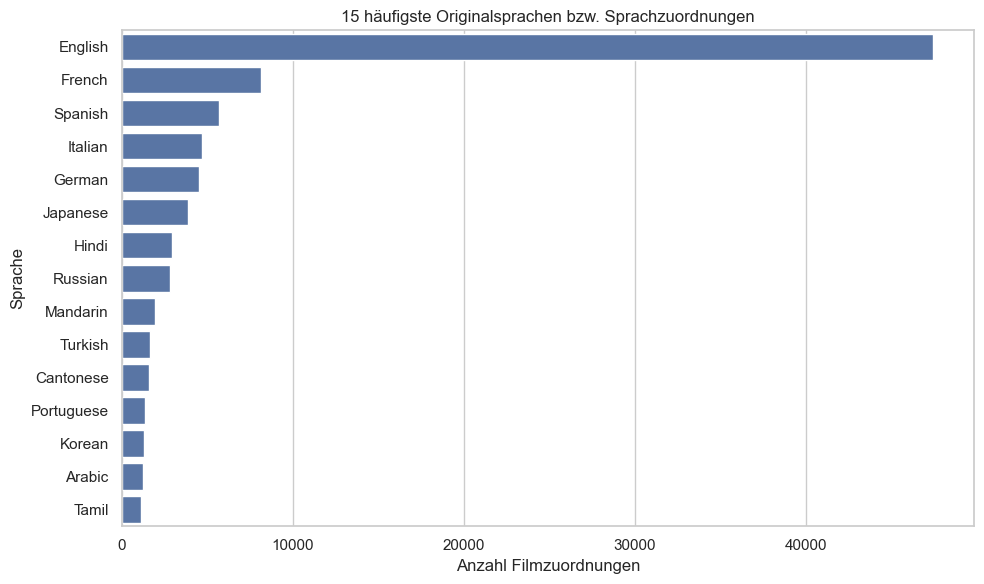

In [12]:
language_df = df.dropna(subset=["language"]).copy()

language_df["language"] = language_df["language"].str.split(",")
language_df = language_df.explode("language")
language_df["language"] = language_df["language"].str.strip()

top_languages = language_df["language"].value_counts().head(15)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_languages.values, y=top_languages.index)

plt.title("15 häufigste Originalsprachen bzw. Sprachzuordnungen")
plt.xlabel("Anzahl Filmzuordnungen")
plt.ylabel("Sprache")
plt.tight_layout()
plt.show()

### Ergebnis: Sprachen
Für **84.954 Filme** ist mindestens eine Sprache angegeben; die Auswertung findet **267 unterschiedliche Spracheinträge**. Am häufigsten ist Englisch (**47.446 Film-Sprach-Zuordnungen**), gefolgt von Französisch (**8.156**), Spanisch (**5.682**), Italienisch (**4.677**), Deutsch (**4.504**), Japanisch (**3.884**) und Hindi (**2.949**). Ein Film kann mehrere Sprachen haben, daher sind dies Zuordnungen. Die Daten zeigen, dass Englisch stark dominiert, gleichzeitig aber viele Möglichkeiten für Empfehlungen aus anderen Sprachräumen vorhanden sind.

## Genres untersuchen

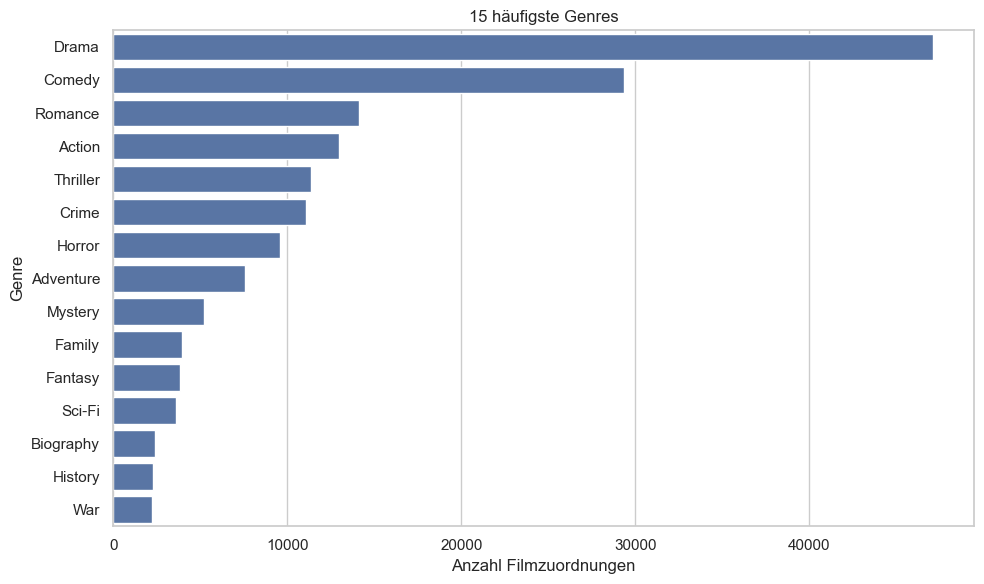

In [13]:
genre_df = df.dropna(subset=["genre"]).copy()

genre_df["genre"] = genre_df["genre"].str.split(",")
genre_df = genre_df.explode("genre")
genre_df["genre"] = genre_df["genre"].str.strip()

top_genres = genre_df["genre"].value_counts().head(15)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_genres.values, y=top_genres.index)

plt.title("15 häufigste Genres")
plt.xlabel("Anzahl Filmzuordnungen")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()

### Ergebnis: Genres
Die Daten enthalten **25 unterschiedliche Genre-Bezeichnungen**. Am häufigsten sind Drama (**47.110 Zuordnungen**) und Komödie (**29.368**), danach Romanze (**14.128**), Action (**12.948**), Thriller (**11.388**) und Krimi (**11.067**). Filme können mehreren Genres zugeordnet sein. Für das Empfehlungssystem sind Genres daher nützliche Präferenzmerkmale; für kulturelle Vielfalt sollten sie aber gemeinsam mit Produktionsland und Sprache betrachtet werden, damit Vielfalt nicht nur bedeutet, andere Genres vorzuschlagen.

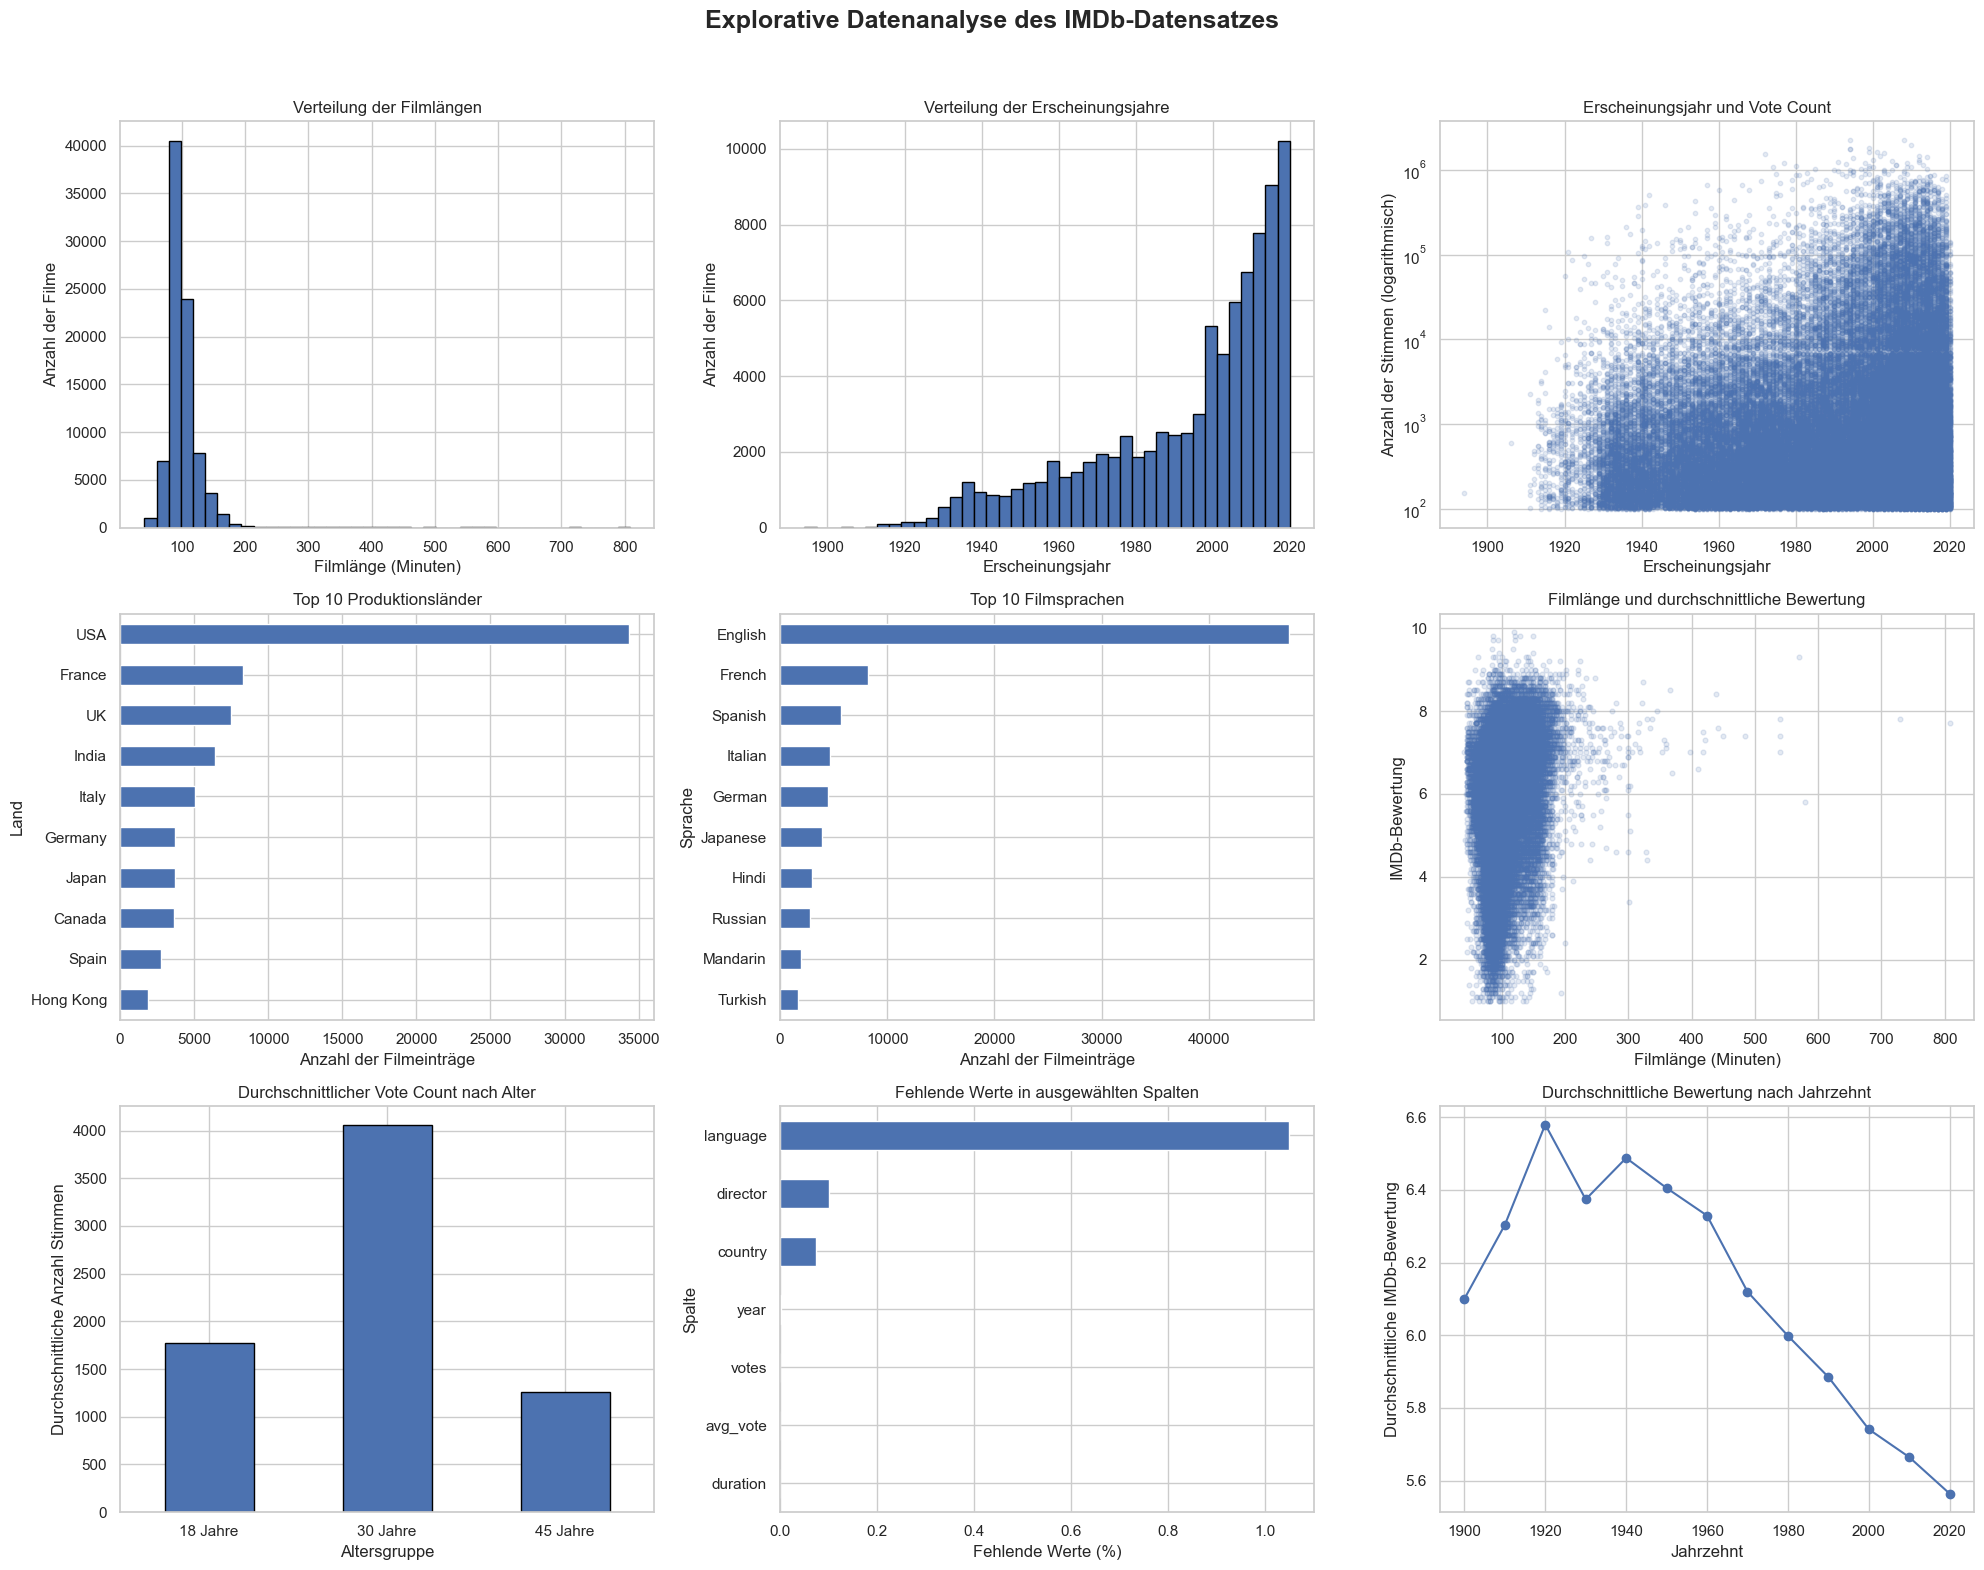

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

# --------------------------------------------------
# 3x3-Grid mit neun explorativen Visualisierungen
# --------------------------------------------------

fig, axes = plt.subplots(3, 3, figsize=(20, 16))
fig.suptitle(
    "Explorative Datenanalyse des IMDb-Datensatzes",
    fontsize=18,
    fontweight="bold"
)

# --------------------------------------------------
# 1. Verteilung der Filmlängen
# --------------------------------------------------
ax = axes[0, 0]

duration_data = pd.to_numeric(df["duration"], errors="coerce").dropna()

ax.hist(duration_data, bins=40, edgecolor="black")
ax.set_title("Verteilung der Filmlängen")
ax.set_xlabel("Filmlänge (Minuten)")
ax.set_ylabel("Anzahl der Filme")


# --------------------------------------------------
# 2. Verteilung der Erscheinungsjahre
# --------------------------------------------------
ax = axes[0, 1]

year_data = pd.to_numeric(df["year"], errors="coerce").dropna()

ax.hist(year_data, bins=40, edgecolor="black")
ax.set_title("Verteilung der Erscheinungsjahre")
ax.set_xlabel("Erscheinungsjahr")
ax.set_ylabel("Anzahl der Filme")


# --------------------------------------------------
# 3. Zusammenhang zwischen Erscheinungsjahr und Vote Count
# --------------------------------------------------
ax = axes[0, 2]

year_data = pd.to_numeric(df["year"], errors="coerce")
votes_data = pd.to_numeric(df["votes"], errors="coerce")

plot_data = pd.DataFrame({
    "year": year_data,
    "votes": votes_data
}).dropna()

plot_data = plot_data[plot_data["votes"] > 0]

ax.scatter(
    plot_data["year"],
    plot_data["votes"],
    alpha=0.15,
    s=10
)

ax.set_yscale("log")
ax.set_title("Erscheinungsjahr und Vote Count")
ax.set_xlabel("Erscheinungsjahr")
ax.set_ylabel("Anzahl der Stimmen (logarithmisch)")


# --------------------------------------------------
# 4. Top 10 Produktionsländer
#    Filme mit mehreren Ländern werden mehrfach gezählt
# --------------------------------------------------
ax = axes[1, 0]

country_counts = Counter()

for countries in df["country"].dropna():
    for country in str(countries).split(","):
        country = country.strip()
        if country:
            country_counts[country] += 1

top_countries = pd.Series(country_counts).nlargest(10).sort_values()

top_countries.plot(kind="barh", ax=ax)
ax.set_title("Top 10 Produktionsländer")
ax.set_xlabel("Anzahl der Filmeinträge")
ax.set_ylabel("Land")


# --------------------------------------------------
# 5. Top 10 Filmsprachen
#    Filme mit mehreren Sprachen werden mehrfach gezählt
# --------------------------------------------------
ax = axes[1, 1]

language_counts = Counter()

for languages in df["language"].dropna():
    for language in str(languages).split(","):
        language = language.strip()
        if language:
            language_counts[language] += 1

top_languages = pd.Series(language_counts).nlargest(10).sort_values()

top_languages.plot(kind="barh", ax=ax)
ax.set_title("Top 10 Filmsprachen")
ax.set_xlabel("Anzahl der Filmeinträge")
ax.set_ylabel("Sprache")


# --------------------------------------------------
# 6. Zusammenhang zwischen Filmlänge und Bewertung
# --------------------------------------------------
ax = axes[1, 2]

duration = pd.to_numeric(df["duration"], errors="coerce")
avg_vote = pd.to_numeric(df["avg_vote"], errors="coerce")

plot_data = pd.DataFrame({
    "duration": duration,
    "avg_vote": avg_vote
}).dropna()

ax.scatter(
    plot_data["duration"],
    plot_data["avg_vote"],
    alpha=0.15,
    s=12
)

ax.set_title("Filmlänge und durchschnittliche Bewertung")
ax.set_xlabel("Filmlänge (Minuten)")
ax.set_ylabel("IMDb-Bewertung")


# --------------------------------------------------
# 7. Vote Count nach Altersgruppe
#    Verwendet altersgruppenspezifische *_votes-Spalten
# --------------------------------------------------
ax = axes[2, 0]

age_vote_columns = {
    "18 Jahre": "allgenders_18age_votes",
    "30 Jahre": "allgenders_30age_votes",
    "45 Jahre": "allgenders_45age_votes"
}

available_age_columns = {
    age: col
    for age, col in age_vote_columns.items()
    if col in df.columns
}

if available_age_columns:
    age_vote_means = {}

    for age, col in available_age_columns.items():
        values = pd.to_numeric(df[col], errors="coerce").dropna()
        values = values[values >= 0]

        if not values.empty:
            age_vote_means[age] = values.mean()

    if age_vote_means:
        pd.Series(age_vote_means).plot(
            kind="bar",
            ax=ax,
            edgecolor="black"
        )
        ax.set_title("Durchschnittlicher Vote Count nach Alter")
        ax.set_xlabel("Altersgruppe")
        ax.set_ylabel("Durchschnittliche Anzahl Stimmen")
        ax.tick_params(axis="x", rotation=0)
    else:
        ax.text(
            0.5, 0.5,
            "Keine gültigen Vote-Count-Daten",
            ha="center", va="center",
            transform=ax.transAxes
        )
        ax.set_title("Vote Count nach Altersgruppe")
else:
    ax.text(
        0.5, 0.5,
        "Altersgruppen-Spalten nicht gefunden.\n"
        "Spaltennamen mit 'age' und 'votes' prüfen.",
        ha="center", va="center",
        transform=ax.transAxes
    )
    ax.set_title("Vote Count nach Altersgruppe")


# --------------------------------------------------
# 8. Anteil fehlender Werte ausgewählter Spalten
# --------------------------------------------------
ax = axes[2, 1]

important_columns = [
    col for col in [
        "year", "duration", "country", "language",
        "director", "avg_vote", "votes"
    ]
    if col in df.columns
]

missing_percent = (
    df[important_columns].isna().mean().mul(100).sort_values()
)

missing_percent.plot(kind="barh", ax=ax)
ax.set_title("Fehlende Werte in ausgewählten Spalten")
ax.set_xlabel("Fehlende Werte (%)")
ax.set_ylabel("Spalte")


# --------------------------------------------------
# 9. Durchschnittliche Bewertung nach Jahrzehnt
# --------------------------------------------------
ax = axes[2, 2]

decade_data = pd.DataFrame({
    "year": pd.to_numeric(df["year"], errors="coerce"),
    "avg_vote": pd.to_numeric(df["avg_vote"], errors="coerce")
}).dropna()

decade_data = decade_data[
    (decade_data["year"] >= 1900) &
    (decade_data["year"] <= 2029)
].copy()

decade_data["Jahrzehnt"] = (
    (decade_data["year"] // 10) * 10
).astype(int)

decade_ratings = decade_data.groupby("Jahrzehnt")["avg_vote"].mean()

ax.plot(
    decade_ratings.index,
    decade_ratings.values,
    marker="o"
)

ax.set_title("Durchschnittliche Bewertung nach Jahrzehnt")
ax.set_xlabel("Jahrzehnt")
ax.set_ylabel("Durchschnittliche IMDb-Bewertung")


# --------------------------------------------------
# Layout optimieren und anzeigen
# --------------------------------------------------
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()